# Modelo de demanda con un año de datos (sep 2025 – ago 2026)

## Salidas por estación y hora

**Problema:** regresión supervisada. Predecir cuántas bicis salen de cada estación en cada hora.

**Qué compara este notebook** (mismo conjunto de prueba, mismas métricas):

| Tipo | Modelo |
| --- | --- |
| Referencias simples | Promedio histórico · Semana pasada · Media de 4 semanas |
| Visto en clase | Regresión lineal · Perceptrón multicapa (MLP) |
| Modelo avanzado | XGBoost global |

**Cómo correrlo:** Restart & Run All, con `RAPIDO = True` para validar que todo funciona (unos minutos) y después `RAPIDO = False` para la corrida final que se reporta. Requiere `trips_clean.parquet` (`python src/ingest.py`) y `pip install -r requirements.txt`.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import modelo as M

# True: corrida corta para validar (menos combinaciones, menos filas, menos épocas)
# False: corrida final para reportar (tarda bastante más y calienta la compu)
RAPIDO = False

N_ITER = 4 if RAPIDO else 12                       # combinaciones de hiperparámetros de XGBoost
MLP_FILAS = 500_000 if RAPIDO else 1_500_000       # filas con las que entrena el MLP
MLP_EPOCAS = 6 if RAPIDO else 15

# --- Un año de datos: lo único distinto a 02_modelo.ipynb
import os
M.FECHA_INICIO = "2025-09-01"     # modelo.py lo lee al cargar; 02_modelo usa "2026-03-01"
FIGURAS = "../figures/anio"
os.makedirs(FIGURAS, exist_ok=True)

## 1. Tratamiento de datos

- Se usan los viajes de 1 a 45 minutos desde el 1 de septiembre de 2025 (un año, hasta el 31 de agosto de 2026) y con estación de origen conocida.
- La tabla es **estación × fecha × hora**, e incluye las horas sin viajes con `salidas = 0`, para que el modelo aprenda también cuándo no hay demanda. Cada estación se considera activa entre su primer y su último viaje.
- **Variables de contexto reciente** (con 7 días o más de rezago): `lag_7d` (lo que salió hace una semana a esa hora), `media_4sem` (promedio de las últimas 4 semanas para ese día y hora) y `nivel_semana` (demanda por hora de la estación hace una a dos semanas). Sirven para detectar cambios de nivel como las vacaciones de verano. Se descartan las filas sin esa historia (primera semana de cada estación).

In [2]:
validos = M.cargar_validos()
estaciones = M.cargar_estaciones()
tabla = M.construir_tabla(validos, estaciones)

print(f"Viajes usados: {len(validos):,}")
print(f"Filas de la tabla (estación-fecha-hora): {len(tabla):,}")
print(f"Estaciones: {tabla['estacion'].nunique()} | Días: {tabla['fecha'].nunique()}")
print(f"% de filas con cero salidas: {(tabla['salidas'] == 0).mean():.1%}")
print(f"Salidas por estación-hora: media {tabla['salidas'].mean():.2f}, máx {tabla['salidas'].max()}")
tabla.head()

Viajes usados: 18,448,239
Filas de la tabla (estación-fecha-hora): 5,788,248
Estaciones: 678 | Días: 356
% de filas con cero salidas: 35.4%
Salidas por estación-hora: media 3.10, máx 203


,estacion,fecha,hora,salidas,dia_semana,es_fin_de_semana,lat,lon,capacidad,cp,alcaldia,lag_7d,media_4sem,nivel_semana
0,1,2025-09-10,0,1,2,0,19.433785,-99.167987,35.0,06500,Cuauhtémoc,1.0,1.0,8.986111
1,1,2025-09-10,1,0,2,0,19.433785,-99.167987,35.0,06500,Cuauhtémoc,0.0,0.0,8.986111
2,1,2025-09-10,2,0,2,0,19.433785,-99.167987,35.0,06500,Cuauhtémoc,0.0,0.0,8.986111
3,1,2025-09-10,3,0,2,0,19.433785,-99.167987,35.0,06500,Cuauhtémoc,0.0,0.0,8.986111
4,1,2025-09-10,4,0,2,0,19.433785,-99.167987,35.0,06500,Cuauhtémoc,0.0,0.0,8.986111


## 2. Partición entrenamiento / prueba

Por fechas, no al azar: se entrena con el pasado y se prueba con el futuro. Una partición aleatoria mezclaría horas del mismo día en ambos lados y filtraría información. Los hiperparámetros se eligen con una validación tomada de los últimos días de entrenamiento; la prueba se usa solo al final.

In [3]:
train, test, corte = M.split_por_fechas(tabla, frac_train=0.8)
print(f"Corte: {corte.date()}")
print(f"Train: {train['fecha'].min().date()} a {train['fecha'].max().date()} ({len(train):,} filas)")
print(f"Test:  {test['fecha'].min().date()} a {test['fecha'].max().date()} ({len(test):,} filas)")
print(f"Salidas promedio por estación-hora: train {train['salidas'].mean():.2f} | test {test['salidas'].mean():.2f}")

Corte: 2026-06-21
Train: 2025-09-10 a 2026-06-20 (4,620,672 filas)
Test:  2026-06-21 a 2026-08-31 (1,167,576 filas)
Salidas promedio por estación-hora: train 3.16 | test 2.88


## 3. Referencias simples (baselines)

Reglas sin aprendizaje que el modelo debe superar:

- **Promedio histórico:** promedio de train por estación, hora y tipo de día (entre semana / fin de semana).
- **Semana pasada:** lo que pasó hace 7 días en esa estación y hora.
- **Media de 4 semanas:** promedio de las 4 semanas previas para esa estación, hora y día de la semana.

In [4]:
y_test = test[M.TARGET].to_numpy()
preds = {
    "Promedio histórico": M.baseline_promedio(train, test),
    "Semana pasada": M.baseline_semana_pasada(test),
    "Media 4 semanas": M.baseline_media_4sem(test),
}
pd.DataFrame({k: M.metricas(y_test, v) for k, v in preds.items()}).T.round(3)

,RMSE,MAE,Sesgo
Promedio histórico,2.616,1.491,0.271
Semana pasada,3.167,1.792,-0.007
Media 4 semanas,2.570,1.485,0.031


## 4. Regresión lineal

Mínimos cuadrados sobre variables **escaladas**: one-hot para estación, hora y día de la semana, y estandarización (z-score) para latitud, longitud, capacidad y las variables de rezago. Los valores faltantes (estaciones sin coordenadas) se imputan con la mediana.

In [5]:
lineal = M.entrenar_lineal(train)
preds["Regresión lineal"] = lineal.predict(test)
print({k: round(v, 3) for k, v in M.metricas(y_test, preds["Regresión lineal"]).items()})

{'RMSE': 2.509, 'MAE': 1.499, 'Sesgo': 0.127}


## 5. Perceptrón multicapa (MLP)

| Elemento | Valor |
| --- | --- |
| Entrada | ~720 variables: one-hot de estación (677), hora (24) y día de la semana (7); z-score de latitud, longitud, capacidad y 3 rezagos; fin de semana |
| Capas ocultas | 2: 64 y 32 neuronas |
| Activación | ReLU (salida lineal, 1 neurona) |
| Pérdida | Error cuadrático medio (MSE) |
| Optimizador | Adam, `learning_rate = 0.001`, lotes de 2048 |
| Regularización | *Early stopping*: se detiene si el RMSE de validación no mejora en 3 épocas |

La curva de aprendizaje muestra el RMSE de entrenamiento y de validación por época: si el de entrenamiento baja y el de validación sube, hay sobreajuste.

época  1  RMSE train=2.572  RMSE val=2.541


época  2  RMSE train=2.531  RMSE val=2.521


época  3  RMSE train=2.502  RMSE val=2.512


época  4  RMSE train=2.483  RMSE val=2.511


época  5  RMSE train=2.470  RMSE val=2.510


época  6  RMSE train=2.459  RMSE val=2.509


época  7  RMSE train=2.453  RMSE val=2.512


época  8  RMSE train=2.448  RMSE val=2.513


época  9  RMSE train=2.441  RMSE val=2.511
early stopping


{'RMSE': 2.461, 'MAE': 1.442, 'Sesgo': 0.18}


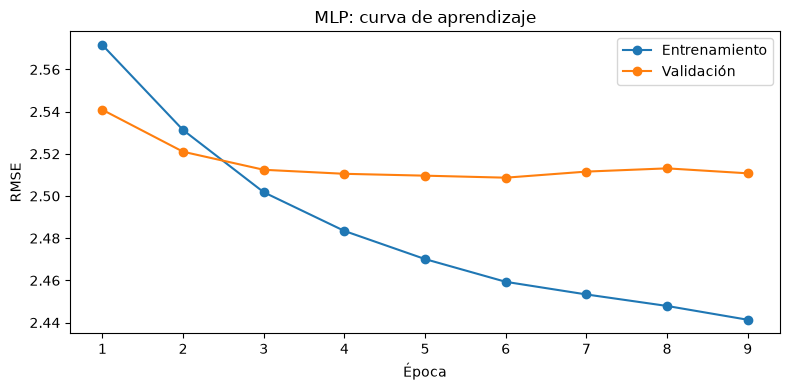

In [6]:
mlp, historial = M.entrenar_mlp(train, capas=(64, 32), lr=1e-3, batch=2048,
                                epocas=MLP_EPOCAS, max_filas=MLP_FILAS)
preds["MLP"] = mlp.predict(test)
print({k: round(v, 3) for k, v in M.metricas(y_test, preds["MLP"]).items()})

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(historial["epoca"], historial["RMSE_train"], marker="o", label="Entrenamiento")
ax.plot(historial["epoca"], historial["RMSE_val"], marker="o", label="Validación")
ax.set_title("MLP: curva de aprendizaje")
ax.set_xlabel("Época")
ax.set_ylabel("RMSE")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIGURAS}/11_curva_aprendizaje_mlp.png", dpi=150)
plt.show()

## 6. XGBoost global

Un solo modelo para las 677 estaciones, con la estación como variable categórica; no necesita escalar las variables. **Hiperparámetros** (búsqueda aleatoria, evaluada en el último 20 % de los días de train, nunca en test):

| Hiperparámetro | Valores probados |
| --- | --- |
| `learning_rate` | 0.03, 0.05, 0.1, 0.2 |
| `max_depth` | 4, 6, 8, 10 |
| `subsample` | 0.6, 0.8, 1.0 |
| `colsample_bytree` | 0.6, 0.8, 1.0 |
| `min_child_weight` | 1, 5, 20 |
| `objective` | error cuadrático o Poisson (las salidas son conteos) |
| `n_estimators` | hasta 1000, con *early stopping* (30 rondas) |

Se usa búsqueda aleatoria y no en malla porque con millones de filas probar todas las combinaciones sería demasiado lento.

In [7]:
busqueda = M.buscar_hiperparametros(train, n_iter=N_ITER)
busqueda

[1/12] RMSE val=2.515  MAE val=1.490  {'subsample': 0.6, 'objective': 'reg:squarederror', 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


[2/12] RMSE val=2.521  MAE val=1.507  {'subsample': 0.6, 'objective': 'reg:squarederror', 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


[3/12] RMSE val=2.514  MAE val=1.481  {'subsample': 1.0, 'objective': 'count:poisson', 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 1.0}


[4/12] RMSE val=2.507  MAE val=1.488  {'subsample': 0.6, 'objective': 'count:poisson', 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


[5/12] RMSE val=2.508  MAE val=1.489  {'subsample': 1.0, 'objective': 'count:poisson', 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.6}


...

[9/12] RMSE val=2.508  MAE val=1.478  {'subsample': 1.0, 'objective': 'count:poisson', 'min_child_weight': 20, 'max_depth': 8, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


[10/12] RMSE val=2.508  MAE val=1.489  {'subsample': 0.8, 'objective': 'reg:squarederror', 'min_child_weight': 20, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 1.0}


[11/12] RMSE val=2.502  MAE val=1.482  {'subsample': 0.6, 'objective': 'count:poisson', 'min_child_weight': 20, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


[12/12] RMSE val=2.518  MAE val=1.482  {'subsample': 0.8, 'objective': 'count:poisson', 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


,subsample,objective,min_child_weight,max_depth,learning_rate,colsample_bytree,mejor_iteracion,RMSE,MAE,Sesgo
0,0.6,count:poisson,20,6,0.05,0.8,994,2.502123,1.482468,0.016935
1,0.6,count:poisson,1,6,0.03,0.8,1000,2.506526,1.487588,0.021338
2,1.0,count:poisson,1,6,0.03,0.6,1000,2.507601,1.488746,0.022339
3,1.0,count:poisson,20,8,0.10,0.8,383,2.507605,1.477877,0.010708
4,0.8,reg:squarederror,20,8,0.03,1.0,295,2.507842,1.488731,0.021239
5,1.0,count:poisson,1,10,0.03,1.0,602,2.514028,1.480942,0.007332
6,0.6,reg:squarederror,1,10,0.10,0.6,70,2.514918,1.489699,0.014995
7,0.8,count:poisson,1,10,0.10,1.0,184,2.517755,1.481886,0.008825
8,0.6,reg:squarederror,1,4,0.10,1.0,373,2.521384,1.506807,0.034378
9,1.0,count:poisson,20,4,0.03,1.0,1000,2.521646,1.500786,0.032802


In [8]:
mejor = busqueda.iloc[0]
params = {}
for k in M.ESPACIO_BUSQUEDA:
    v = mejor[k]
    params[k] = v if k == "objective" else (int(v) if k in ("max_depth", "min_child_weight") else float(v))
n_arboles = int(mejor["mejor_iteracion"])
print("Mejores hiperparámetros:", params, "| árboles:", n_arboles)

modelo = M.entrenar_xgb(train, params, n_arboles)
preds["XGBoost"] = np.clip(modelo.predict(test[M.FEATURES]), 0, None)
print({k: round(v, 3) for k, v in M.metricas(y_test, preds["XGBoost"]).items()})

Mejores hiperparámetros: {'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.6, 'colsample_bytree': 0.8, 'min_child_weight': 20, 'objective': 'count:poisson'} | árboles: 994


{'RMSE': 2.457, 'MAE': 1.416, 'Sesgo': 0.127}


## 7. Comparación de modelos

In [9]:
resultados = pd.DataFrame({k: M.metricas(y_test, v) for k, v in preds.items()}).T
ref = resultados.loc["Promedio histórico"]
resultados["Mejora RMSE vs promedio histórico"] = 1 - resultados["RMSE"] / ref["RMSE"]
resultados["Mejora MAE vs promedio histórico"] = 1 - resultados["MAE"] / ref["MAE"]
resultados = resultados.sort_values("RMSE")
mejor_modelo = resultados.drop(index=["Promedio histórico", "Semana pasada", "Media 4 semanas"]).index[0]
print(f"Mejor modelo entrenado (menor RMSE): {mejor_modelo}")
resultados.round(3)

Mejor modelo entrenado (menor RMSE): XGBoost


,RMSE,MAE,Sesgo,Mejora RMSE vs promedio histórico,Mejora MAE vs promedio histórico
XGBoost,2.457,1.416,0.127,0.061,0.050
MLP,2.461,1.442,0.180,0.059,0.033
Regresión lineal,2.509,1.499,0.127,0.041,-0.006
Media 4 semanas,2.570,1.485,0.031,0.017,0.004
Promedio histórico,2.616,1.491,0.271,0.000,0.000
Semana pasada,3.167,1.792,-0.007,-0.211,-0.202


In [10]:
# Sobreajuste: error en una muestra de train contra error en prueba
muestra = train.sample(min(300_000, len(train)), random_state=0)
y_m = muestra[M.TARGET].to_numpy()
modelos = {"Regresión lineal": lineal, "MLP": mlp,
           "XGBoost": type("W", (), {"predict": lambda self, d: np.clip(modelo.predict(d[M.FEATURES]), 0, None)})()}
filas = {}
for nombre, m in modelos.items():
    filas[nombre] = {"RMSE train": M.metricas(y_m, m.predict(muestra))["RMSE"],
                     "RMSE prueba": M.metricas(y_test, preds[nombre])["RMSE"]}
sobre = pd.DataFrame(filas).T
sobre["Diferencia"] = sobre["RMSE prueba"] - sobre["RMSE train"]
sobre.round(3)

,RMSE train,RMSE prueba,Diferencia
Regresión lineal,2.637,2.509,-0.127
MLP,2.511,2.461,-0.050
XGBoost,2.482,2.457,-0.025


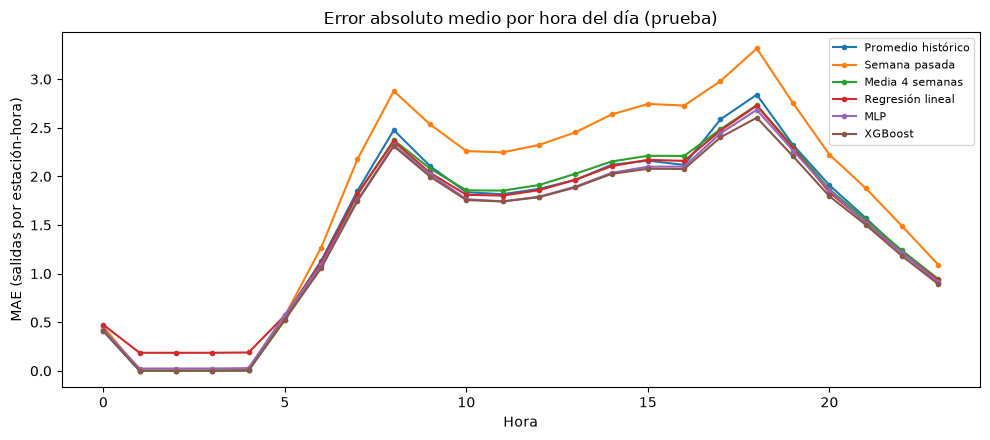

In [11]:
# Error por hora del día (MAE), todos los modelos
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre, p in preds.items():
    e = M.error_por(test, p, "hora")
    ax.plot(e.index, e["MAE"], marker="o", markersize=3, label=nombre)
ax.set_title("Error absoluto medio por hora del día (prueba)")
ax.set_xlabel("Hora")
ax.set_ylabel("MAE (salidas por estación-hora)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIGURAS}/09_error_por_hora.png", dpi=150)
plt.show()

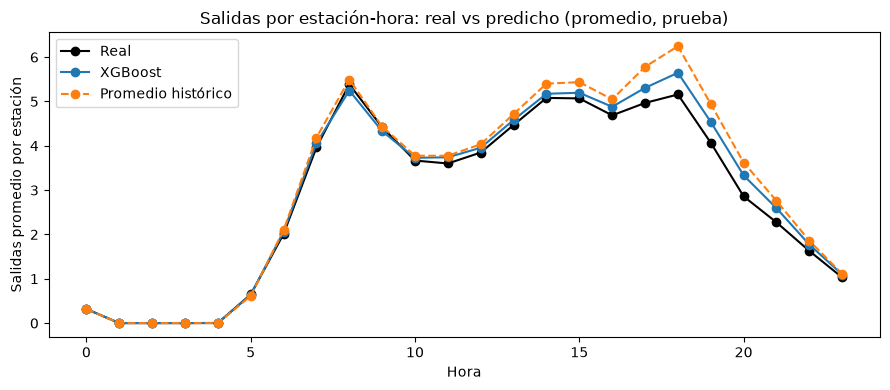

In [12]:
# Real vs predicho: promedio por hora en el periodo de prueba
d = test[["hora"]].copy()
d["Real"] = y_test
for nombre in ["Promedio histórico", mejor_modelo]:
    d[nombre] = preds[nombre]
por_hora = d.groupby("hora").mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(por_hora.index, por_hora["Real"], marker="o", color="black", label="Real")
ax.plot(por_hora.index, por_hora[mejor_modelo], marker="o", label=mejor_modelo)
ax.plot(por_hora.index, por_hora["Promedio histórico"], marker="o", linestyle="--", label="Promedio histórico")
ax.set_title("Salidas por estación-hora: real vs predicho (promedio, prueba)")
ax.set_xlabel("Hora")
ax.set_ylabel("Salidas promedio por estación")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIGURAS}/08_real_vs_predicho.png", dpi=150)
plt.show()

In [13]:
# Error por alcaldía y estaciones con más error, del mejor modelo
p_mejor = preds[mejor_modelo]
display(M.error_por(test, p_mejor, "alcaldia").sort_values("MAE", ascending=False).round(3))

por_est = M.error_por(test, p_mejor, "estacion").sort_values("MAE", ascending=False)
print("10 estaciones con más error (MAE):")
por_est.head(10).round(3)

,RMSE,MAE,n
alcaldia,,,
Cuauhtémoc,3.100,1.776,418176
Miguel Hidalgo,2.526,1.471,240192
Benito Juárez,1.825,1.178,368064
Álvaro Obregón,1.622,0.917,29376
Azcapotzalco,1.356,0.904,48384
Coyoacán,1.299,0.849,62424
desconocido,0.086,0.015,960


10 estaciones con más error (MAE):


,RMSE,MAE,n
estacion,,,
271-272,16.612,6.957,1728
548,6.550,4.119,1728
27,6.685,4.073,1728
237-238,6.544,3.969,1728
14,6.530,3.832,1728
273-274,8.582,3.589,1728
194,6.664,3.551,1728
43,5.489,3.451,1728
29,5.313,3.442,1728


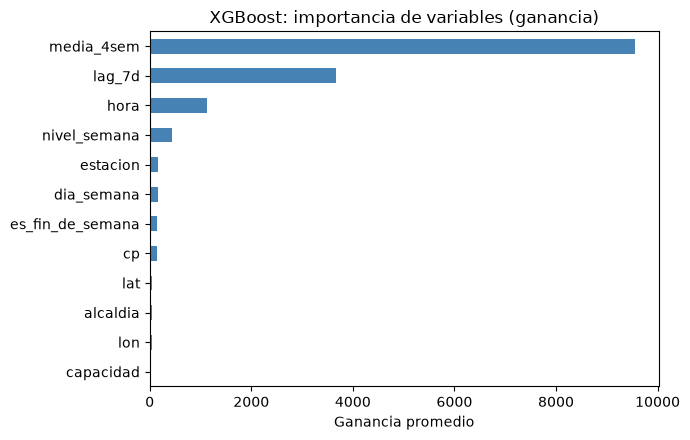

In [14]:
# Importancia de variables de XGBoost (ganancia promedio)
imp = pd.Series(modelo.get_booster().get_score(importance_type="gain")).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
imp.plot.barh(ax=ax, color="steelblue")
ax.set_title("XGBoost: importancia de variables (ganancia)")
ax.set_xlabel("Ganancia promedio")
plt.tight_layout()
plt.savefig(f"{FIGURAS}/10_importancia_variables.png", dpi=150)
plt.show()

In [15]:
# Guarda las métricas para el reporte y las slides
sufijo = "_rapido" if RAPIDO else ""
resultados.round(4).to_csv(f"../data/processed/resultados_modelo_anio{sufijo}.csv")
sobre.round(4).to_csv(f"../data/processed/sobreajuste_modelo_anio{sufijo}.csv")
busqueda.round(4).to_csv(f"../data/processed/busqueda_hiperparametros_anio{sufijo}.csv", index=False)
print("Guardado. RAPIDO =", RAPIDO)

Guardado. RAPIDO = False


## Comparación con la corrida de 6 meses

Métricas de prueba de esta corrida contra `resultados_modelo.csv` (mar – ago 2026). Ojo: con un año el corte 80/20 cae en otra fecha, así que **cambian tanto el train como la prueba**; la comparación es indicativa, no un experimento controlado.

Primera pista de que la diferencia viene del periodo de prueba y no del modelo: "Semana pasada" no usa el entrenamiento y aun así empeora lo mismo que los demás (3.055 → 3.167). La comparación controlada está en la sección siguiente.

In [16]:
seis = pd.read_csv("../data/processed/resultados_modelo.csv", index_col=0)
print(f"Prueba con un año: {test['fecha'].min().date()} a {test['fecha'].max().date()} | con 6 meses: 2026-07-28 a 2026-08-31")
comparacion = pd.DataFrame({
    "RMSE 6 meses": seis["RMSE"], "RMSE 1 año": resultados["RMSE"],
    "MAE 6 meses": seis["MAE"], "MAE 1 año": resultados["MAE"],
    "Sesgo 6 meses": seis["Sesgo"], "Sesgo 1 año": resultados["Sesgo"],
}).loc[resultados.index]
comparacion.to_csv("../data/processed/comparacion_6meses_vs_anio.csv")
comparacion.round(3)

Prueba con un año: 2026-06-21 a 2026-08-31 | con 6 meses: 2026-07-28 a 2026-08-31


,RMSE 6 meses,RMSE 1 año,MAE 6 meses,MAE 1 año,Sesgo 6 meses,Sesgo 1 año
XGBoost,2.370,2.457,1.383,1.416,0.060,0.127
MLP,2.419,2.461,1.396,1.442,0.040,0.180
Regresión lineal,2.453,2.509,1.466,1.499,0.043,0.127
Media 4 semanas,2.494,2.570,1.449,1.485,-0.028,0.031
Promedio histórico,2.559,2.616,1.448,1.491,0.171,0.271
Semana pasada,3.055,3.167,1.747,1.792,-0.019,-0.007


## Comparación justa: misma prueba que la corrida de 6 meses

Para aislar el efecto de tener más historia, aquí se prueba en **el mismo periodo que `02_modelo.ipynb` (28 jul – 31 ago 2026)** y se entrena con todo lo anterior: 10 sep 2025 – 27 jul 2026 (~10.5 meses) contra 10 mar – 27 jul 2026 (~4.5 meses) en la corrida de 6 meses. Todo lo demás es igual: mismas variables, mismos modelos, misma configuración del MLP, y XGBoost con los hiperparámetros y el número de árboles elegidos en la sección 6 (su validación fue mar – jun 2026, así que no ve este periodo de prueba).

Control: "Semana pasada" y "Media 4 semanas" no usan el entrenamiento, así que deben dar exactamente lo mismo que en la corrida de 6 meses. Si coinciden, las filas de prueba son las mismas.

In [17]:
CORTE_6M = pd.Timestamp("2026-07-28")    # el corte de 02_modelo.ipynb
train_j = tabla[tabla["fecha"] < CORTE_6M]
test_j = tabla[tabla["fecha"] >= CORTE_6M]
y_j = test_j[M.TARGET].to_numpy()
print(f"Train: {train_j['fecha'].min().date()} a {train_j['fecha'].max().date()} ({len(train_j):,} filas)")
print(f"Test:  {test_j['fecha'].min().date()} a {test_j['fecha'].max().date()} ({len(test_j):,} filas; en 02_modelo: 567,072)")

preds_j = {
    "Promedio histórico": M.baseline_promedio(train_j, test_j),
    "Semana pasada": M.baseline_semana_pasada(test_j),
    "Media 4 semanas": M.baseline_media_4sem(test_j),
}
preds_j["Regresión lineal"] = M.entrenar_lineal(train_j).predict(test_j)
mlp_j, _ = M.entrenar_mlp(train_j, capas=(64, 32), lr=1e-3, batch=2048,
                          epocas=MLP_EPOCAS, max_filas=MLP_FILAS)
preds_j["MLP"] = mlp_j.predict(test_j)
xgb_j = M.entrenar_xgb(train_j, params, n_arboles)
preds_j["XGBoost"] = np.clip(xgb_j.predict(test_j[M.FEATURES]), 0, None)

Train: 2025-09-10 a 2026-07-27 (5,221,176 filas)
Test:  2026-07-28 a 2026-08-31 (567,072 filas; en 02_modelo: 567,072)


época  1  RMSE train=2.614  RMSE val=2.546


época  2  RMSE train=2.590  RMSE val=2.543


época  3  RMSE train=2.573  RMSE val=2.543


época  4  RMSE train=2.560  RMSE val=2.542


época  5  RMSE train=2.550  RMSE val=2.541


época  6  RMSE train=2.542  RMSE val=2.541


época  7  RMSE train=2.536  RMSE val=2.542


época  8  RMSE train=2.532  RMSE val=2.544


época  9  RMSE train=2.529  RMSE val=2.546
early stopping


In [18]:
res_j = pd.DataFrame({k: M.metricas(y_j, v) for k, v in preds_j.items()}).T.sort_values("RMSE")
justa = pd.DataFrame({
    "RMSE 6 meses": seis["RMSE"], "RMSE 1 año": res_j["RMSE"],
    "MAE 6 meses": seis["MAE"], "MAE 1 año": res_j["MAE"],
    "Sesgo 6 meses": seis["Sesgo"], "Sesgo 1 año": res_j["Sesgo"],
}).loc[res_j.index]
justa["Cambio RMSE"] = justa["RMSE 1 año"] / justa["RMSE 6 meses"] - 1
justa["Cambio MAE"] = justa["MAE 1 año"] / justa["MAE 6 meses"] - 1

control = justa.loc[["Semana pasada", "Media 4 semanas"], ["RMSE 6 meses", "RMSE 1 año"]]
print("Control (no usan train, deben coincidir):", "OK" if (control.diff(axis=1).iloc[:, 1].abs() < 1e-3).all() else "NO coinciden")
justa.round(4).to_csv("../data/processed/comparacion_justa_6meses_vs_anio.csv")
justa.style.format({c: "{:+.1%}" if c.startswith("Cambio") else "{:.3f}" for c in justa.columns})

Control (no usan train, deben coincidir): OK


,RMSE 6 meses,RMSE 1 año,MAE 6 meses,MAE 1 año,Sesgo 6 meses,Sesgo 1 año,Cambio RMSE,Cambio MAE
XGBoost,2.370,2.395,1.383,1.390,0.060,0.072,+1.1%,+0.5%
Regresión lineal,2.453,2.450,1.466,1.466,0.043,0.059,-0.1%,-0.0%
MLP,2.419,2.460,1.396,1.465,0.041,0.342,+1.7%,+4.9%
Media 4 semanas,2.494,2.494,1.449,1.449,-0.028,-0.028,-0.0%,+0.0%
Promedio histórico,2.559,2.605,1.448,1.467,0.171,0.206,+1.8%,+1.3%
Semana pasada,3.055,3.055,1.747,1.747,-0.019,-0.019,+0.0%,+0.0%


## 8. Discusión

**¿Qué modelo ganó y por cuánto?** XGBoost, con RMSE 2.457 y MAE 1.416 en la prueba (21 jun – 31 ago 2026). Mejora 6.1 % en RMSE al promedio histórico y 4.4 % a la referencia más fuerte, "Media 4 semanas" (2.570). El MLP queda prácticamente empatado en RMSE (2.461), pero con más MAE (1.442) y más sesgo. La regresión lineal baja el RMSE (2.509), pero su MAE (1.499) es peor que el de las referencias simples. Las mejoras son modestas: la mayor parte de lo predecible ya lo captura el promedio de las últimas 4 semanas.

**Sesgo.** Todos los modelos predicen de más: XGBoost +0.13 salidas por estación-hora, MLP +0.18 y promedio histórico +0.27. La prueba cae en verano, con menos demanda que el entrenamiento (2.88 contra 3.16 de media). La figura 08 muestra que el exceso se concentra de 16 a 21 h. Los rezagos lo corrigen en parte: "Media 4 semanas" casi no tiene sesgo (+0.03), porque sigue el nivel reciente. Pero los modelos lo combinan con patrones de meses de más demanda.

**Sobreajuste.** No hay. En los tres modelos el RMSE en una muestra de train es *mayor* que en prueba (XGBoost 2.482 contra 2.457), porque el periodo de prueba tiene menos demanda y menos varianza. El MLP se detuvo por *early stopping* en la época 9, y su error de validación se estabilizó desde la época 4 (≈ 2.51).

**Dónde falla.** El error se concentra donde hay más viajes: Cuauhtémoc (MAE 1.78) y Miguel Hidalgo (1.47), contra Coyoacán (0.85). La estación pareada `271-272` (Buenavista) domina el error, con RMSE 16.6 y MAE 6.96, el doble que la siguiente (548, MAE 4.12). Le siguen 27, `237-238` y 14. Son las mismas estaciones problemáticas que en la corrida de 6 meses.

**Variables.** Dominan los rezagos: `media_4sem` muy por encima del resto, luego `lag_7d`, `hora` y `nivel_semana`. Estación, día, código postal y coordenadas aportan casi nada una vez que se conoce el nivel reciente de la estación (figura 10).

**¿Sirvió tener un año de datos?** No, con este modelo.
- La comparación indicativa (corte 80/20) sale peor con un año (XGBoost 2.457 contra 2.370), pero ahí cambia también la prueba: incluye de 21 jun a 27 jul, y "Semana pasada" empeora igual sin usar el entrenamiento.
- Con la **misma prueba** (28 jul – 31 ago), el control coincide exacto. Entrenar con ~10.5 meses en lugar de ~4.5 deja la regresión lineal igual (2.450 contra 2.453) y empeora un poco a XGBoost (2.395 contra 2.370, +1.1 %) y al MLP (2.460 contra 2.419, +1.7 %). El MLP además sube su sesgo de +0.04 a +0.34.
- Interpretación: el modelo predice sobre todo con rezagos de las últimas 4 semanas, y no tiene variables de estación del año, clima ni vacaciones. Así, los meses de otoño e invierno no le enseñan nada útil para agosto y diluyen el patrón reciente. Las diferencias de ~1 % vienen de una sola corrida por modelo (XGBoost y MLP tienen aleatoriedad), y los hiperparámetros de XGBoost se eligieron con otra ventana. Lo que se puede afirmar es que **más historia no mejoró la predicción**, no que la empeore.

**Limitaciones.** No hay clima ni festivos o vacaciones escolares: julio y agosto son vacaciones y temporada de lluvias, con lluvia en las tardes, una posible causa del exceso de 16 a 21 h. Las estaciones pareadas suman dos estaciones físicas. La demanda es observada: si una estación está vacía, no registra salidas. Y los CSV traen viajes con fechas fuera del mes (desde 2022), que se descartan con `FECHA_INICIO`.

**Posibles Mejoras.**
- Clima por hora, en especial lluvia.
- Calendario de festivos y vacaciones.
- Para aprovechar el año completo: variables de mes o temporada, o dar más peso a las semanas recientes, en lugar de solo agregar filas.
- Cercanía a Metro y Metrobús.
- Tratar aparte las estaciones de muy alta demanda como `271-272`.
